# B5 · Ground-truth labels

Which cars failed, when they stopped, and when the first symptom showed. The rule is written down in
[`labelling_rule.md`](labelling_rule.md) **before** any tuning; this notebook shows what it produces and is where
each onset is reviewed by hand.

```bash
.venv/bin/python analysis/fetch_causes.py --seasons 2023 2024 2025   # Wikipedia classification tables (cached)
.venv/bin/python analysis/build_labels.py --seasons 2023 2024 2025   # -> analysis/labels.csv
```

Sources: cause from the **Wikipedia race-classification table** (Jolpica says only "Retired"); stop and onset from
the car's own **telemetry** (B2 clean samples, 2023–2024 so far); `rc_stopped` from **race control**.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)   # numpy 'generic' timedelta unit, from pandas internals

from fw47_core import labels as lb
from fw47_core.clean import neutralised_periods

RAW = Path('..') / 'data' / 'parquet'
CLEAN = Path('..') / 'data' / 'clean'
TUNE = [2023, 2024]
labels = pd.read_csv('labels.csv')
for c in ('stop_time', 'last_moving', 'onset_auto'):
    labels[c] = pd.to_datetime(labels[c], format='ISO8601', utc=True)
print(f'{len(labels)} rows: cars that did not finish, {labels.season.min()}–{labels.season.max()}')

182 rows: cars that did not finish, 2023–2025


## 1. Events per season and class

In [2]:
counts = labels.pivot_table(index='season', columns='class', values='driver_number', aggfunc='size', fill_value=0)
counts = counts[['mechanical', 'ambiguous', 'crash', 'excluded']]
counts.loc['total'] = counts.sum()
counts

class,mechanical,ambiguous,crash,excluded
season,,,,
2023,21,8,28,9
2024,18,0,31,6
2025,12,3,33,13
total,51,11,92,28


In [3]:
# Causes behind each class (all seasons)
labels.groupby(['class', 'cause']).size().rename('n').reset_index().sort_values(['class', 'n'], ascending=[True, False]) \
    .groupby('class').head(8).set_index(['class', 'cause'])

n
class      cause                  
ambiguous  Undertray             5
           Floor                 1
           Handling              1
           Hydraulics/Accident   1
           Rear wing             1
           Suspension            1
           Suspension/Accident   1
crash      Collision            38
           Collision damage     24
           Accident             22
           Puncture              2
           Spun off              2
           Accident damage       1
           Damage                1
           Incident damage       1
excluded   Plank wear            4
           Withdrew              4
           Accident              2
           Hydraulics            2
           Skid block            2
           Underweight           2
           Brakes                1
           Car damaged           1
mechanical Engine               17
           Brakes                8
           Gearbox               4
           Hydraulics            4
           Overheating           4
           Oil leak              2
           Chassis               1
           Clutch                1

## 2. Where the cars stopped, and whether a symptom shows

Only the tuning seasons have car data so far. "Onset" means the rule found a departure from the car's own
previous laps that runs into the stop.

In [4]:
t = labels[labels.season.isin(TUNE) & (labels['class'] != 'excluded')].copy()
t['onset found'] = t['onset_auto'].notna()
where = t.pivot_table(index='class', columns=['stop_where', 'onset found'], values='driver_number', aggfunc='size', fill_value=0)
where

onset found,False,True,False,True
class,,,,
ambiguous,5,2,0,1
crash,19,10,16,14
mechanical,18,9,0,12


In [5]:
t.groupby(['class', 'onset_reason']).size().unstack(fill_value=0)

onset_reason,crawl,crawl+slow+lift,lift,no departure,no departure before the stop,no reference laps,rpm_off (no reference laps),slow,slow+lift
class,,,,,,,,,
ambiguous,0,0,1,2,2,1,0,2,0
crash,0,1,2,6,4,25,1,18,2
mechanical,1,0,5,8,7,3,0,12,3


**Most mechanical retirements end in the pit lane, and look normal until the car turns in.** The team saw a
problem in its own telemetry (which OpenF1 doesn't publish) and called the car in. Speed, throttle, rpm and gear show
nothing a public-data detector could catch. The detector's realistic target is the cars that **stopped on
track**, plus the few that visibly limped to the pits.

mechanical, 2023–2024: 39; stopped on track: 12; with a proposed onset: 21


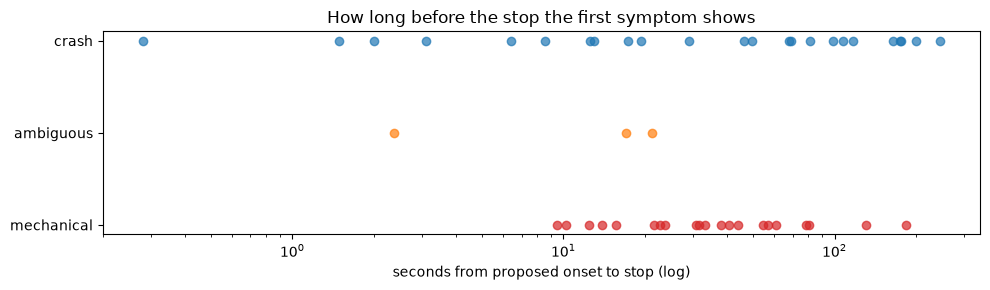

In [6]:
m = t[t['class'] == 'mechanical']
print(f"mechanical, 2023–2024: {len(m)}; stopped on track: {(m.stop_where == 'track').sum()}; "
      f"with a proposed onset: {m.onset_auto.notna().sum()}")
fig, ax = plt.subplots(figsize=(10, 3))
for c, colour in [('mechanical', 'tab:red'), ('ambiguous', 'tab:orange'), ('crash', 'tab:blue')]:
    x = t.loc[(t['class'] == c) & t.lead_s.notna(), 'lead_s']
    ax.scatter(x, np.full(len(x), c), color=colour, alpha=.7)
ax.set(xscale='log', xlabel='seconds from proposed onset to stop (log)', title='How long before the stop the first symptom shows')
plt.tight_layout()

## 3. Review: every mechanical and ambiguous retirement, 2023–2024

Speed against the car's own reference (grey: slowest of its last 3 clean laps before the incident lap and the lap before it; purple dashed: its earlier in-laps,
when it ended in the pit lane). Green: pit lane and the drive into it (masked). Yellow: SC / VSC / red flag (only
crawling and impossible states count). Red dashed: proposed onset. Dotted: stop. Lower panel: throttle, rpm/150 and
gear×10.

Review rule (section 5 of the labelling rule): put `auto`, a UTC timestamp, or `none` in `onset_reviewed`, with a
reason in `review_note` whenever it isn't `auto`.

47 plots


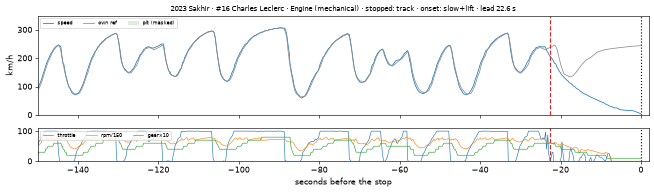

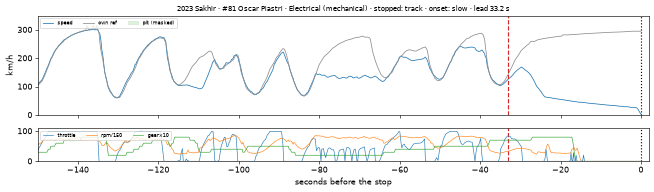

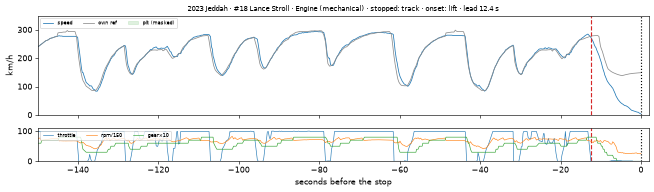

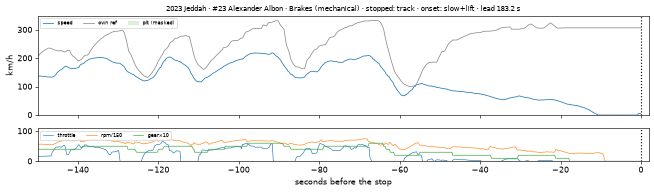

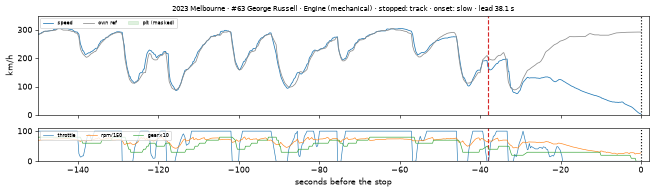

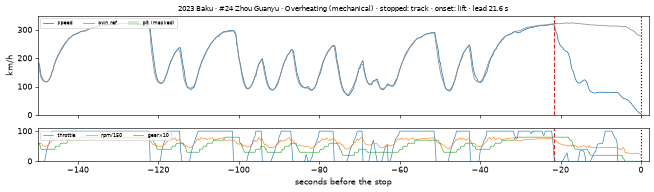

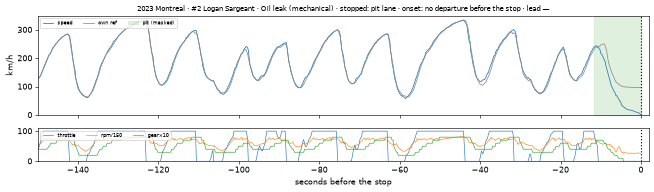

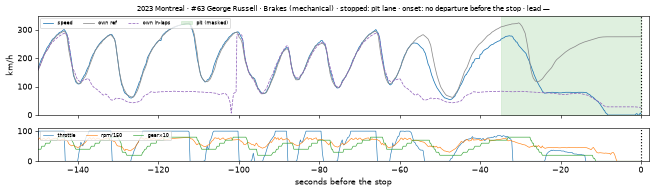

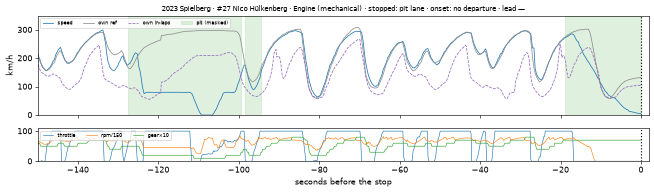

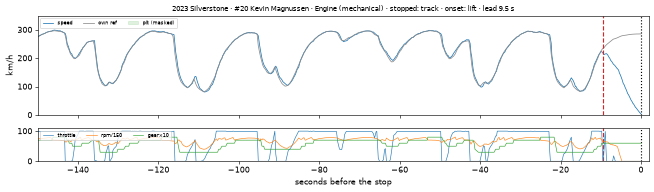

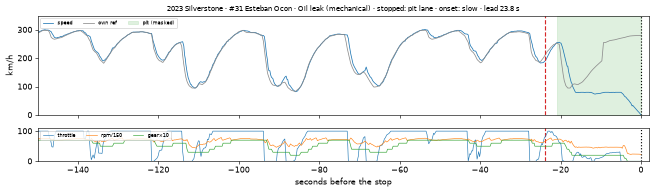

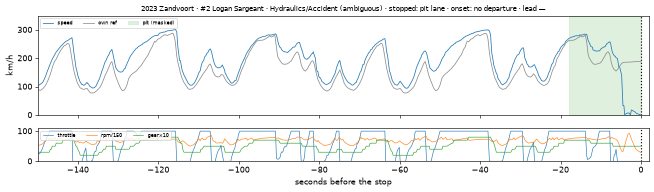

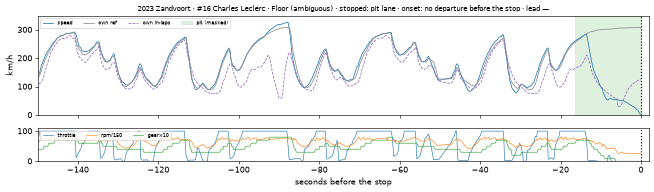

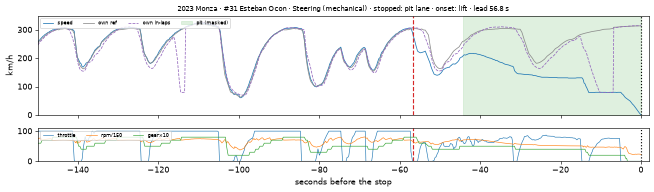

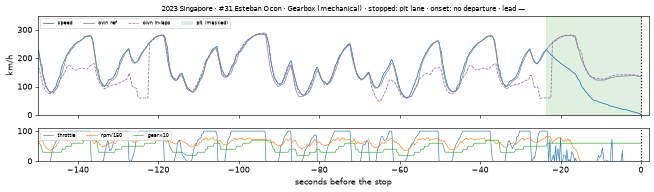

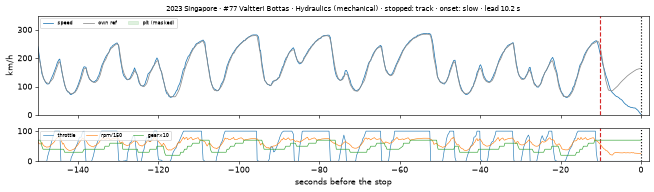

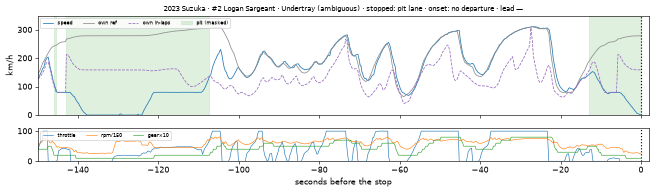

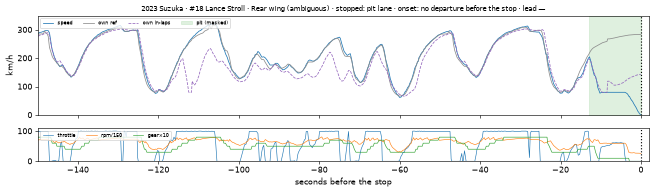

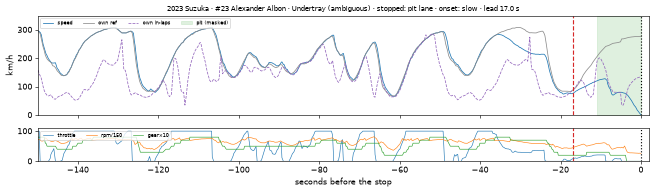

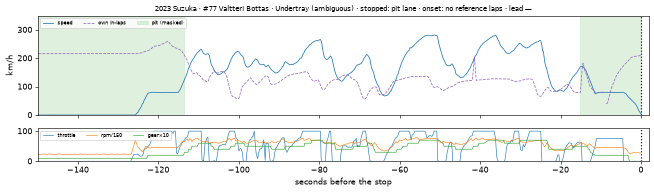

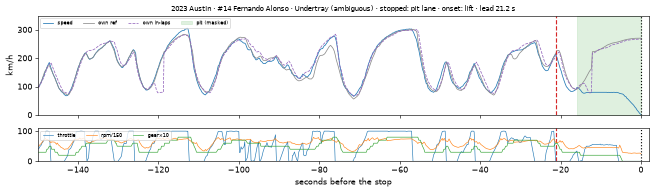

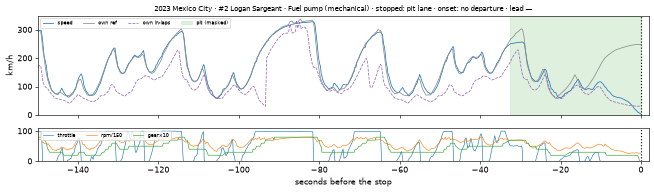

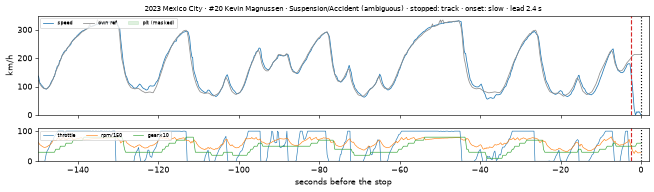

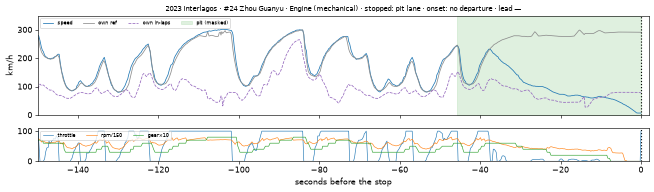

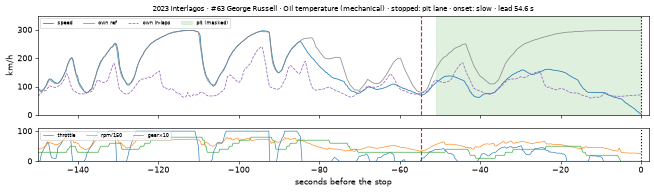

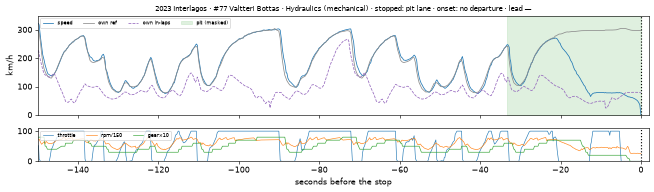

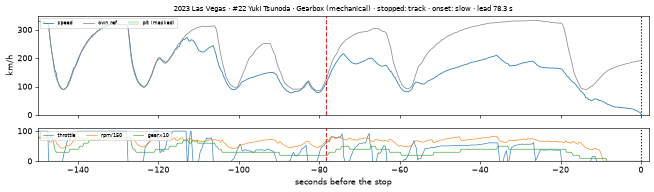

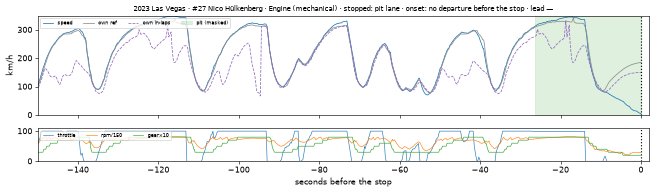

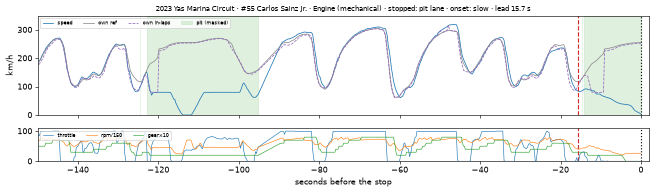

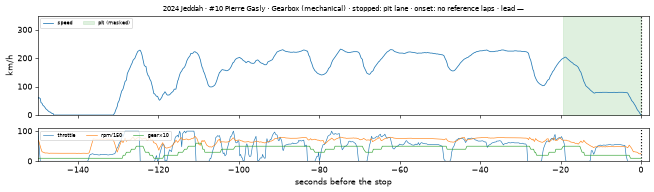

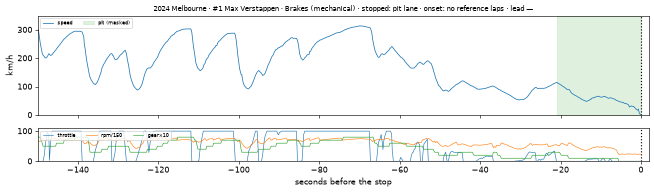

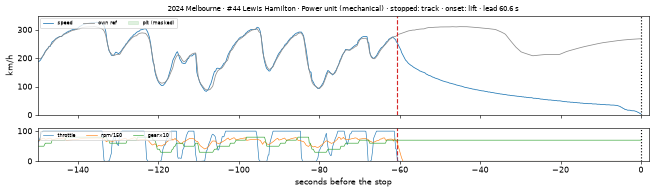

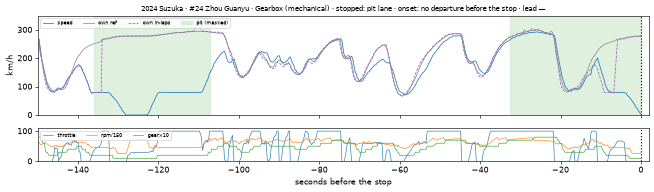

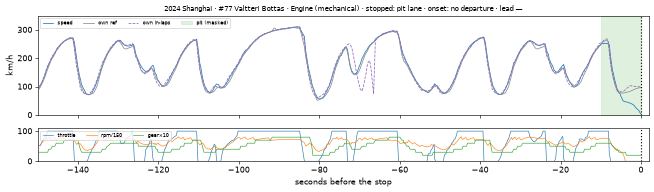

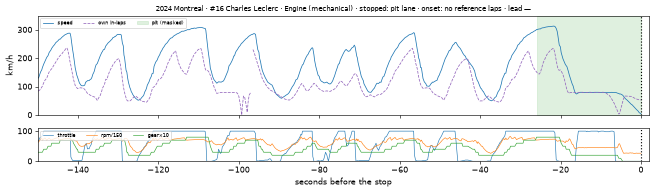

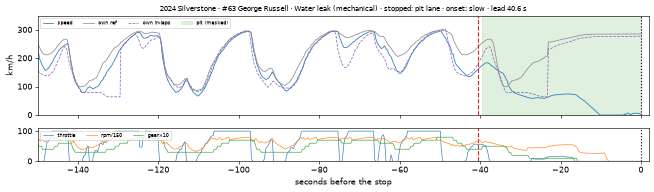

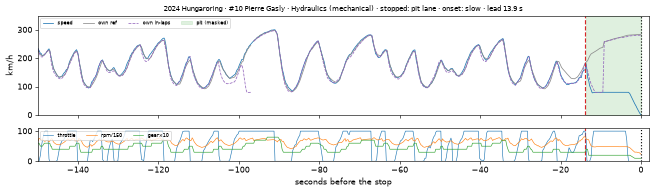

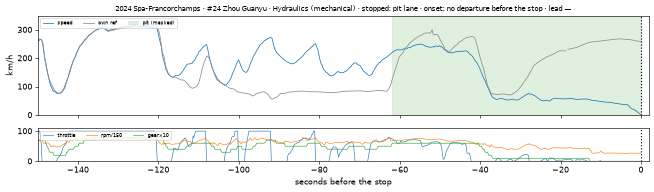

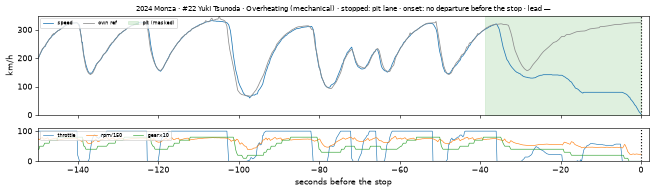

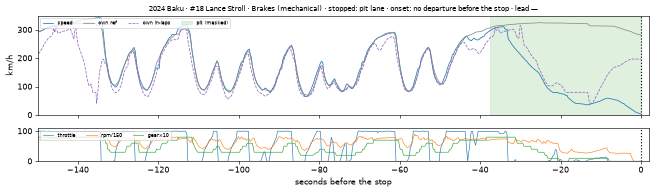

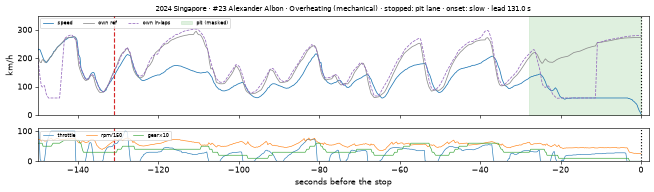

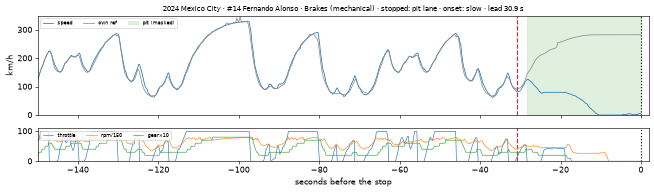

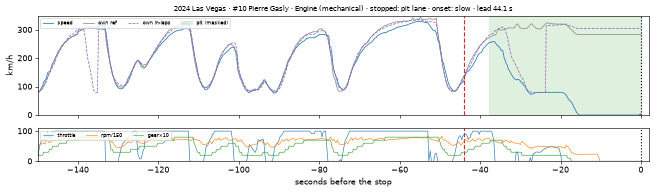

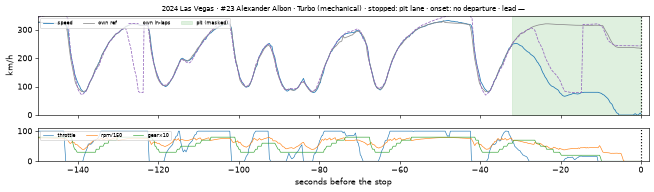

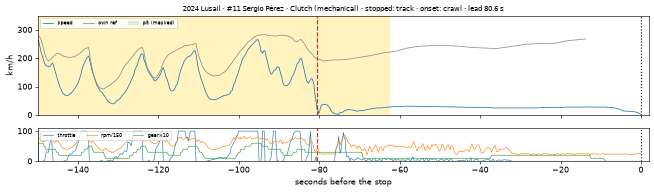

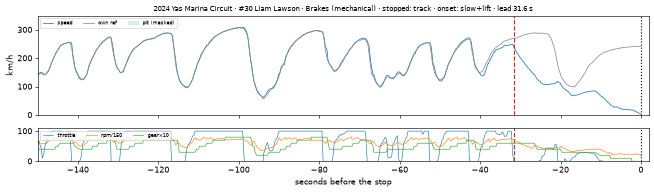

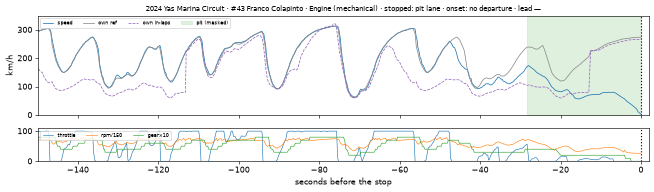

In [7]:
COLS = ['driver_number', 'date', 'lap_number', 'speed', 'rpm', 'throttle', 'n_gear', 'brake', 'lap_distance_m',
        'clean', 'pit_in', 'x', 'y']
_cache = {}

def session(season, key):
    if (season, key) not in _cache:
        _cache.clear()
        s = pd.read_parquet(CLEAN / 'samples' / f'season={season}' / f'{key}.parquet', columns=COLS)
        s = s.sort_values(['driver_number', 'date']).reset_index(drop=True)
        for c in ('clean', 'pit_in'):
            s[c] = s[c].astype('boolean').fillna(False).astype(bool)
        pit = pd.read_parquet(RAW / 'pit' / f'season={season}' / f'{key}.parquet')
        rc = pd.read_parquet(RAW / 'race_control' / f'season={season}' / f'{key}.parquet')
        lane = lb.pit_lane_points(s, pit)
        line = s.loc[s['clean'], ['x', 'y']].dropna().to_numpy(float)[::5]
        _cache[(season, key)] = (s, lane, line, neutralised_periods(rc))
    return _cache[(season, key)]

def review_plot(r, window_s=150):
    s, lane, line, periods = session(r.season, r.session_key)
    car = s[s.driver_number == r.driver_number]
    stop = r.stop_time if pd.notna(r.stop_time) else r.last_moving
    lap = int(r.stop_lap)
    upto = car[car.date <= stop]
    masked = lb.in_pit_lane(upto, lane, line)
    if r.stop_where == 'pit lane':
        masked |= lb.pit_approach(upto, lane)
    w = upto.assign(masked=masked)
    w = w[w.date >= stop - pd.Timedelta(seconds=window_s)]
    x = (w.date - stop).dt.total_seconds()
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(12, 3.6), sharex=True, gridspec_kw={'height_ratios': [3, 1]})
    a1.plot(x, w.speed, lw=1, label='speed')
    ref = lb.reference(car, lb.reference_laps(sorted(car.loc[car.clean & (car.lap_number < lap), 'lap_number'].unique()), lap))
    if ref is not None:
        a1.plot(x, np.interp(w.lap_distance_m, ref.centre_m, ref.speed), lw=1, color='0.55', label='own ref')
    il = sorted(car.loc[car.pit_in & (car.lap_number < lap), 'lap_number'].unique())
    iref = lb.reference(car, il, min_laps=1) if (il and r.stop_where == 'pit lane') else None
    if iref is not None:
        a1.plot(x, np.interp(w.lap_distance_m, iref.centre_m, iref.speed), lw=1, color='tab:purple', ls='--', label='own in-laps')
    a1.fill_between(x, 0, 350, where=w.masked, color='tab:green', alpha=.15, step='mid', label='pit (masked)')
    for k, v in periods.items():
        for a, b in (v if k != 'yellow' else []):
            if b > stop - pd.Timedelta(seconds=window_s) and a < stop:
                a1.axvspan(max((a - stop).total_seconds(), -window_s), min((b - stop).total_seconds(), 0), color='gold', alpha=.25)
    if pd.notna(r.onset_auto):
        for a in (a1, a2):
            a.axvline((r.onset_auto - stop).total_seconds(), color='tab:red', ls='--')
    for a in (a1, a2):
        a.axvline(0, color='k', ls=':')
    a1.set(ylim=(0, 350), xlim=(-window_s, 2), ylabel='km/h')
    lead = f'{r.lead_s:.1f} s' if pd.notna(r.lead_s) else '—'
    a1.set_title(f'{r.season} {r.track} · #{r.driver_number} {r.driver} · {r.cause} ({r.cls}) · '
                 f'stopped: {r.stop_where} · onset: {r.onset_reason} · lead {lead}', fontsize=9)
    a2.plot(x, w.throttle, lw=.8, label='throttle'); a2.plot(x, w.rpm / 150, lw=.8, label='rpm/150')
    a2.plot(x, w.n_gear * 10, lw=.8, label='gear×10')
    a2.set(ylim=(0, 110), xlabel='seconds before the stop')
    a1.legend(fontsize=7, loc='upper left', ncol=5); a2.legend(fontsize=7, loc='upper left', ncol=3)
    plt.tight_layout(); plt.show()

review = t[t['class'].isin(['mechanical', 'ambiguous']) & t.stop_lap.notna()].sort_values(['season', 'round'])
review = review.rename(columns={'class': 'cls'})   # 'class' can't be an itertuples attribute
print(f'{len(review)} plots')
plt.rcParams['figure.dpi'] = 55   # 47 plots: keep the notebook small
for r in review.itertuples():
    review_plot(r)

## 4. Negatives

Clean laps (B2) of cars that finished the race (labelling rule, section 6).

In [8]:
rows = []
for season in TUNE:
    cls = pd.read_parquet(RAW / 'wiki_classification' / f'season={season}' / 'classification.parquet')
    keys = labels[labels.season == season].drop_duplicates('round').set_index('round')['session_key']
    fin = cls[cls.finished].assign(session_key=lambda d: d['round'].map(keys)).dropna(subset=['session_key'])
    laps = pd.concat([pd.read_parquet(f) for f in (CLEAN / 'laps' / f'season={season}').glob('*.parquet')])
    neg = lb.negative_laps(laps, fin.astype({'session_key': int}))
    rows.append(dict(season=season, finishers=len(fin), negative_laps=len(neg),
                     car_hours=neg.lap_duration.sum() / 3600, share_of_clean_laps=len(neg) / laps.clean.sum()))
pd.DataFrame(rows).set_index('season').round(3)

,finishers,negative_laps,car_hours,share_of_clean_laps
season,,,,
2023,334,15505,382.630,0.806
2024,364,16627,414.658,0.798


## 5. Findings

**182 non-finishers in 2023–2025, 51 of them mechanical.** 39 are in the tuning seasons (21 in 2023, 18 in 2024) and
12 in the 2025 test season. There are another 11 ambiguous causes (failure or contact damage), 92 crashes and
collisions, and 28 excluded (DNS, DSQ, withdrawn, driver illness, a pit-stop error). The causes come from the
Wikipedia classification tables, because Jolpica says only "Retired". That also catches cars that failed late but
were still classified.

**Most mechanical retirements can't be seen in public telemetry.** Of the 39 in the tuning seasons, 27 ended in the
pit lane, and 23 of those looked normal right up to the pit entry: no slowdown, no lift, no impossible state. The
team retired the car on its own data (temperatures, pressures), which OpenF1 doesn't publish. So the honest ceiling for a
public-data detector is the **12 cars that stopped on track**, plus **4** that visibly limped to the pits: 16 events
in two seasons (after the first-pass onset review, still to be confirmed).

**On-track failures give a short warning.** For the 12 that stopped on track the median reviewed onset is 32 s before
the stop (range 9–183 s; Magnussen, Silverstone 2023: 9 s; Hamilton, Melbourne 2024: 61 s; Albon, Jeddah 2023: 183 s
of limping). The 4 that limped to the pits showed it 57–131 s before they stopped. B6's "lead time before the car
stopped" is measured against that.

**Race control rarely names stopped cars.** Only 4 "CAR N STOPPED" messages in three seasons, so "stopped on
track" comes from telemetry (stop position against the pit lane learned from each race's pit stops), not from
race-control messages.

**The onset rule compares the car with itself.** Departures are measured against the car's own last 3 clean laps,
not the field baseline the B4 detector uses, so B6's time-to-signal isn't circular. Building and reviewing it showed four
traps, each fixed in the rule:
- OpenF1's car-off sentinel looked like slow driving (Zhou, Interlagos 2023: a stop 27 minutes late).
- Braking into the pit lane looked like a symptom (Sargeant, Montreal 2023).
- Masking safety-car periods hid a car crawling under one (Pérez, Lusail 2024).
- The lap before the incident was both searched and a reference lap, so a car that limped for its last full lap was
  compared with itself (Piastri, Sakhir 2023). Found in the review; fixed before any tuning, which changed 17 of the 47
  proposals (see the change note in the labelling rule).

**Negatives:** ~16,000 clean laps per season (~400 car-hours) from cars that finished, about 80% of all clean laps.

**What this means for B6**
- Recall on ~15 visible mechanical events will have wide intervals (12 of 15 has a 95% Wilson interval of
  roughly 55–93%), so B6 reports intervals, as planned.
- Report recall separately for: on track, limped to the pits, and "no visible symptom" (which no public-data
  detector can catch, and which should be said plainly rather than hidden in a low recall number).
- Crashes are a separate class, with their own recall.

**Onset review: first pass done, to be confirmed.** Each plot in section 3 has `auto`, a timestamp or `none` in
`onset_reviewed` (14 / 4 / 29), with a note for every non-`auto` row. Two judgement calls are flagged in the notes:
six "pit-entry cases", where the only departure is in the last seconds before the pit entry (all set to `none`), and
Verstappen, Melbourne 2024 (a timestamp without reference laps). The in-lap reference is also weaker than it should
be: one slow in-lap (e.g. under a red flag) suppresses `slow` over the whole lap; the review judged those cars against
their racing laps. After confirmation, commit `labels.csv`. The 2025 rows get stops and onsets once the 2025 car data is downloaded,
and are reviewed under the same rule before the single test run.